In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import pairwise_distances_argmin_min
from sklearn.ensemble import IsolationForest
from sklearn.mixture import GaussianMixture

In [ ]:
cluster_data = pd.read_csv('/content/drive/MyDrive/Applied Machine Learning/SDSS-Gaia_5950stars.csv')

In [ ]:
valid_columns = [col for col in ["J","H","K","C_FE","N_FE","O_FE","NA_FE","MG_FE","AL_FE","SI_FE","CA_FE","TI_FE","P_FE","S_FE","V_FE","CR_FE","MN_FE","FE_H","CO_FE","NI_FE","CE_FE","E","Energy","Lz"] if col in cluster_data.columns]
cluster_data = cluster_data[valid_columns]

In [ ]:
cluster_data.head()

,J,H,K,C_FE,N_FE,O_FE,NA_FE,MG_FE,AL_FE,SI_FE,CA_FE,S_FE,V_FE,CR_FE,FE_H,CO_FE,NI_FE,E,Energy,Lz
0,13.761,12.882,12.733,-0.55730,0.121530,-0.058410,-0.656198,-0.098967,-0.762219,-0.087906,0.031485,0.542042,-0.649838,-0.531586,-1.14850,-0.14573,-0.195007,0.306008,22115.660768,1012.248998
1,14.134,13.344,13.250,-0.55490,0.216510,0.120292,-0.077998,-0.030772,-0.465619,0.118681,0.102875,0.176822,-0.500538,-0.282986,-1.05660,-0.22613,-0.071108,0.391866,41705.742939,3540.648917
2,14.646,14.024,13.744,-0.57650,0.440610,0.059940,0.247772,-0.013754,-0.213769,-0.042152,0.036315,0.579082,0.339922,0.516684,-0.98495,0.02452,-0.057557,0.629223,-10492.912912,-835.158712
3,14.208,13.426,13.346,-0.57267,-0.054657,-0.001759,0.133502,-0.194887,-0.626319,0.057021,-0.084456,0.142352,0.231272,-1.088186,-1.16200,-0.36663,-0.151808,0.333420,9371.299309,35.651705
4,13.819,13.031,12.882,-0.59562,0.120780,0.045731,-0.006498,-0.078007,-0.570919,0.035366,0.191595,0.678072,-0.971138,-0.010586,-1.33410,-0.17063,-0.064307,0.347582,12680.876488,-297.262299


In [ ]:
cluster_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5950 entries, 0 to 5949
Data columns (total 20 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   J       5950 non-null   float64
 1   H       5950 non-null   float64
 2   K       5950 non-null   float64
 3   C_FE    5950 non-null   float64
 4   N_FE    5950 non-null   float64
 5   O_FE    5950 non-null   float64
 6   NA_FE   5950 non-null   float64
 7   MG_FE   5950 non-null   float64
 8   AL_FE   5950 non-null   float64
 9   SI_FE   5950 non-null   float64
 10  CA_FE   5950 non-null   float64
 11  S_FE    5950 non-null   float64
 12  V_FE    5950 non-null   float64
 13  CR_FE   5950 non-null   float64
 14  FE_H    5950 non-null   float64
 15  CO_FE   5950 non-null   float64
 16  NI_FE   5950 non-null   float64
 17  E       5950 non-null   float64
 18  Energy  5950 non-null   float64
 19  Lz      5950 non-null   float64
dtypes: float64(20)
memory usage: 929.8 KB


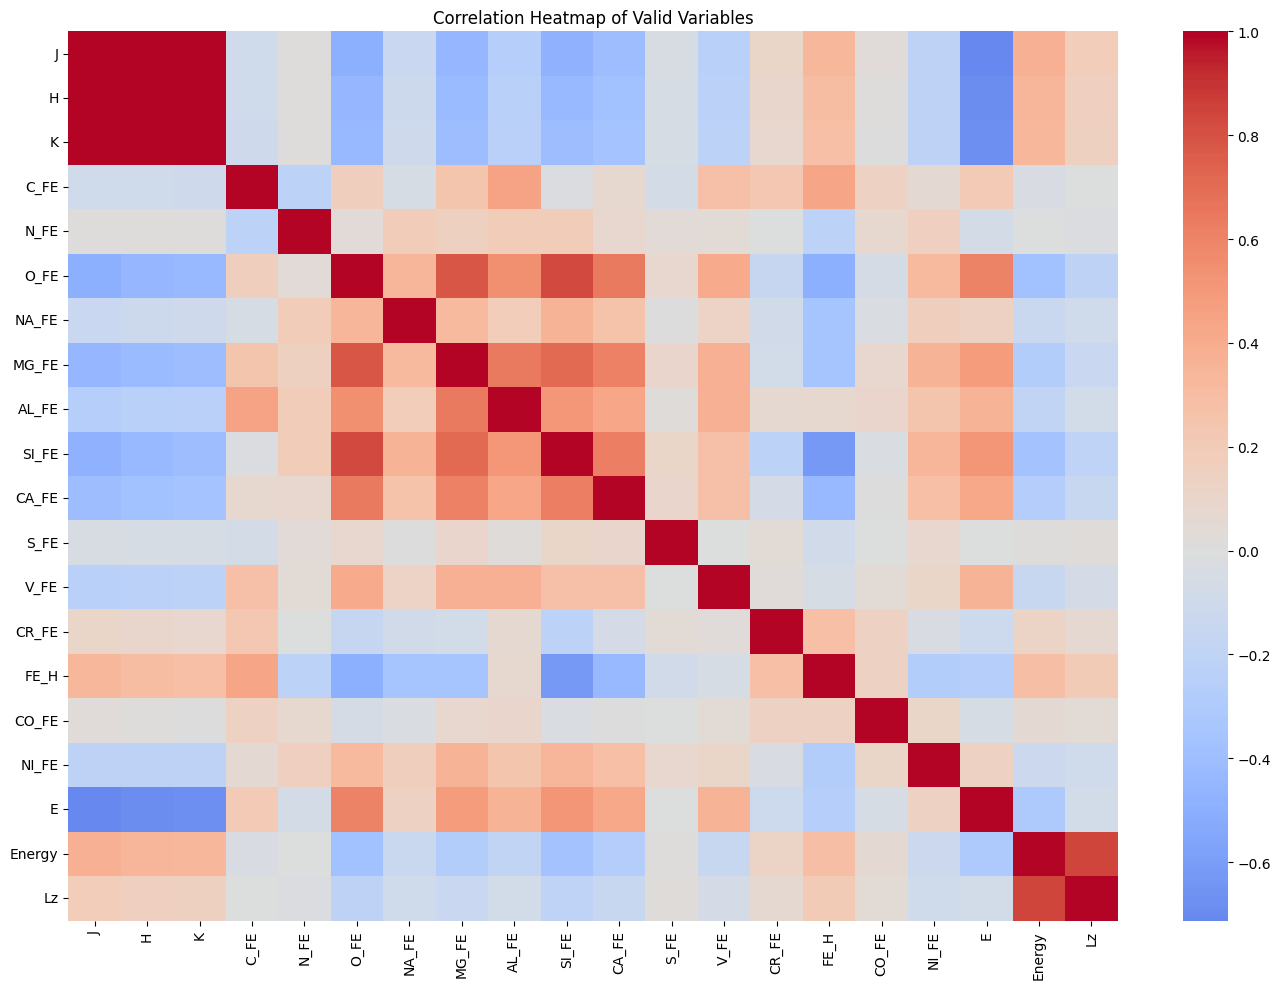

In [ ]:
# Plot correlation heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(cluster_data.corr(), annot=False, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Heatmap of Valid Variables")
plt.tight_layout()
plt.show()

## Finding the top 7 features

In [ ]:
# Step 1: Compute variance of each valid variable
variances = cluster_data.var().sort_values(ascending=False)

# Step 2: Identify highly correlated pairs (Pearson correlation > 0.9)
correlation_matrix = cluster_data.corr().abs()
upper_triangle = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))

# Step 3: Filter out highly correlated features (keep only one from each highly correlated group)
excluded = set()
selected_features = []

for col in variances.index:
    if col not in excluded:
        selected_features.append(col)
        # Exclude all other features highly correlated with this one
        correlated_features = upper_triangle.columns[upper_triangle.loc[col] > 0.9].tolist()
        excluded.update(correlated_features)

    if len(selected_features) == 7:
        break

selected_features


['Energy', 'Lz', 'J', 'V_FE', 'NA_FE', 'FE_H', 'S_FE']

In [ ]:
variables_list = pd.DataFrame(selected_features)

In [ ]:
variables_list.to_csv('/content/drive/MyDrive/Applied Machine Learning/Clustering_MohammadhadiShahhosseini_VariableList.csv', index=False, header = False)

In [ ]:
# Subset data with selected features
X = cluster_data[selected_features]

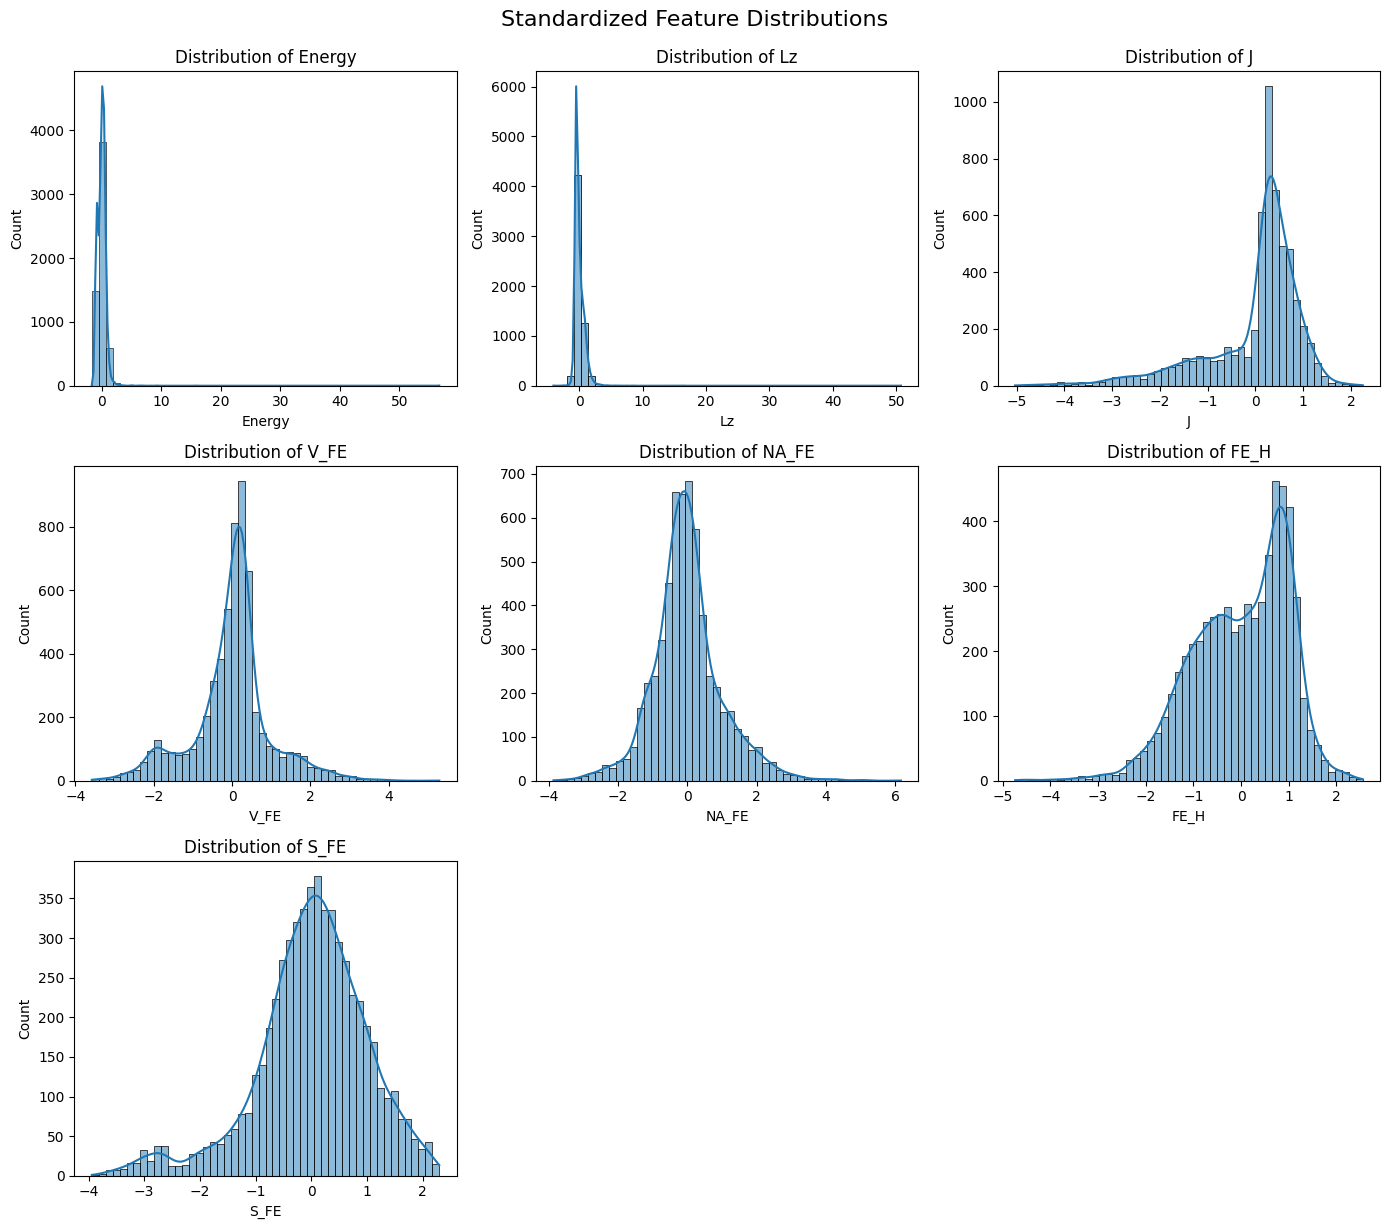

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=selected_features)

# Plot distributions for each selected feature
plt.figure(figsize=(14, 12))
for i, col in enumerate(selected_features):
    plt.subplot(3, 3, i + 1)
    sns.histplot(X_scaled_df[col], bins=50, kde=True)
    plt.title(f'Distribution of {col}')
    plt.tight_layout()

plt.suptitle("Standardized Feature Distributions", fontsize=16, y=1.02)
plt.show()

# Models

## KMeans

### Finding K

In [ ]:
# Step 1: Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 2: Find the best number of clusters using silhouette score (for k from 5 to 50)
silhouette_scores = []
cluster_range = range(5, 50)

for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

# Find best k
best_k = cluster_range[np.argmax(silhouette_scores)]
best_k, silhouette_scores[np.argmax(silhouette_scores)]


(5, np.float64(0.2391674047354978))

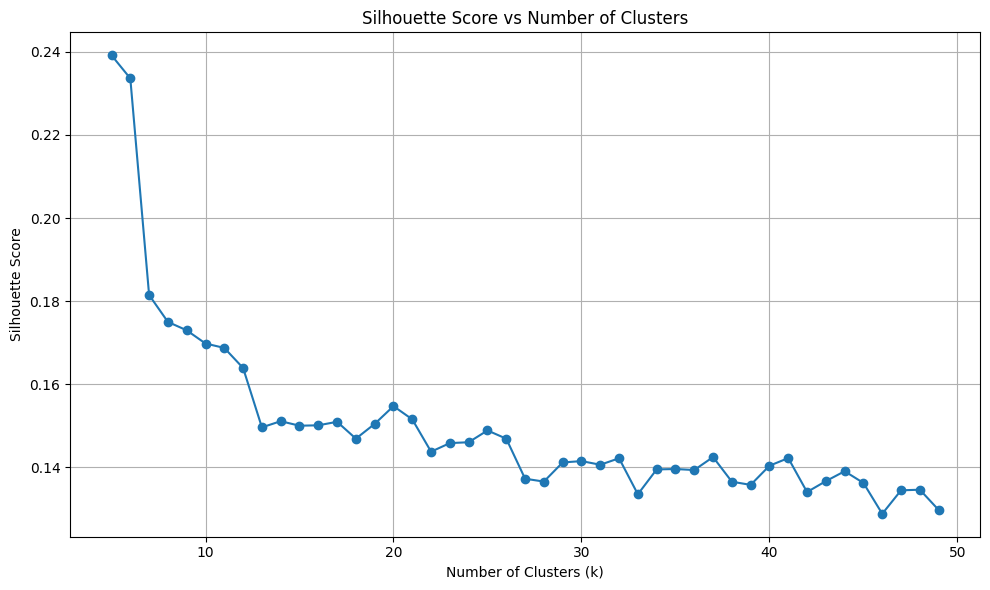

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(cluster_range, silhouette_scores, marker='o')
plt.title("Silhouette Score vs Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.tight_layout()
plt.show()

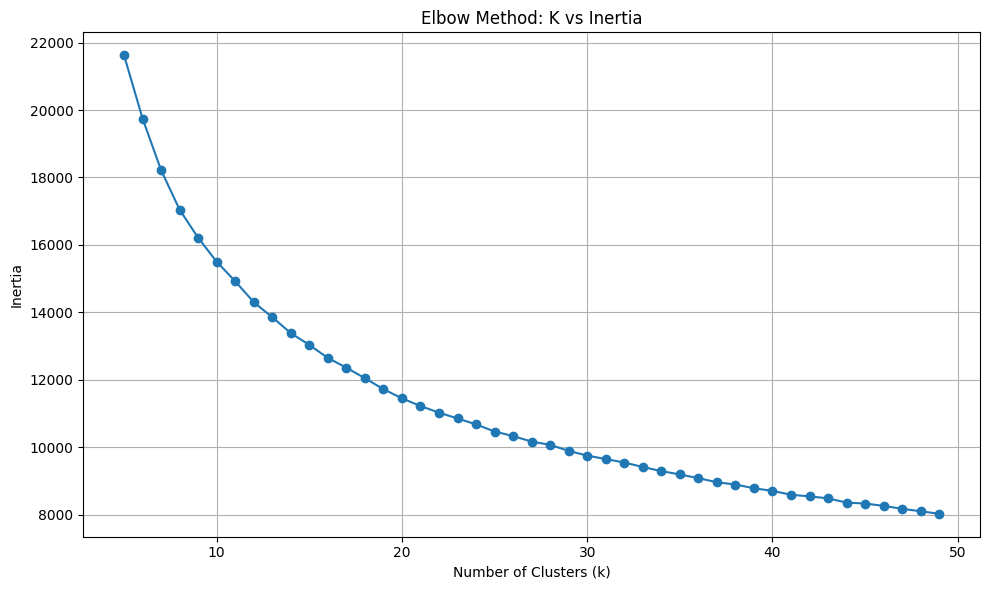

In [ ]:
# Elbow method – compute inertia for each k
inertia_values = []

for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

# Plot elbow curve
plt.figure(figsize=(10, 6))
plt.plot(cluster_range, inertia_values, marker='o')
plt.title("Elbow Method: K vs Inertia")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.grid(True)
plt.tight_layout()
plt.show()


## KMeans

In [ ]:
# Apply KMeans with best k
final_kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
X['Cluster'] = final_kmeans.fit_predict(X_scaled)

# Show first few rows with assigned cluster
X[['Energy', 'Lz', 'J', 'V_FE', 'NA_FE', 'FE_H', 'S_FE', 'Cluster']].head()


<ipython-input-15-a19bd5fb6fbe>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Cluster'] = final_kmeans.fit_predict(X_scaled)


,Energy,Lz,J,V_FE,NA_FE,FE_H,S_FE,Cluster
0,22115.660768,1012.248998,13.761,-0.649838,-0.656198,-1.14850,0.542042,2
1,41705.742939,3540.648917,14.134,-0.500538,-0.077998,-1.05660,0.176822,2
2,-10492.912912,-835.158712,14.646,0.339922,0.247772,-0.98495,0.579082,1
3,9371.299309,35.651705,14.208,0.231272,0.133502,-1.16200,0.142352,1
4,12680.876488,-297.262299,13.819,-0.971138,-0.006498,-1.33410,0.678072,2


In [ ]:
X['Cluster'].reset_index().to_csv('/content/drive/MyDrive/Applied Machine Learning/Clustering_MohammadhadiShahhosseini_rawKMeans.csv', index=False, header = False)

<ipython-input-17-e617f19a67e6>:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['TSNE-1'] = X_tsne[:, 0]
<ipython-input-17-e617f19a67e6>:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['TSNE-2'] = X_tsne[:, 1]


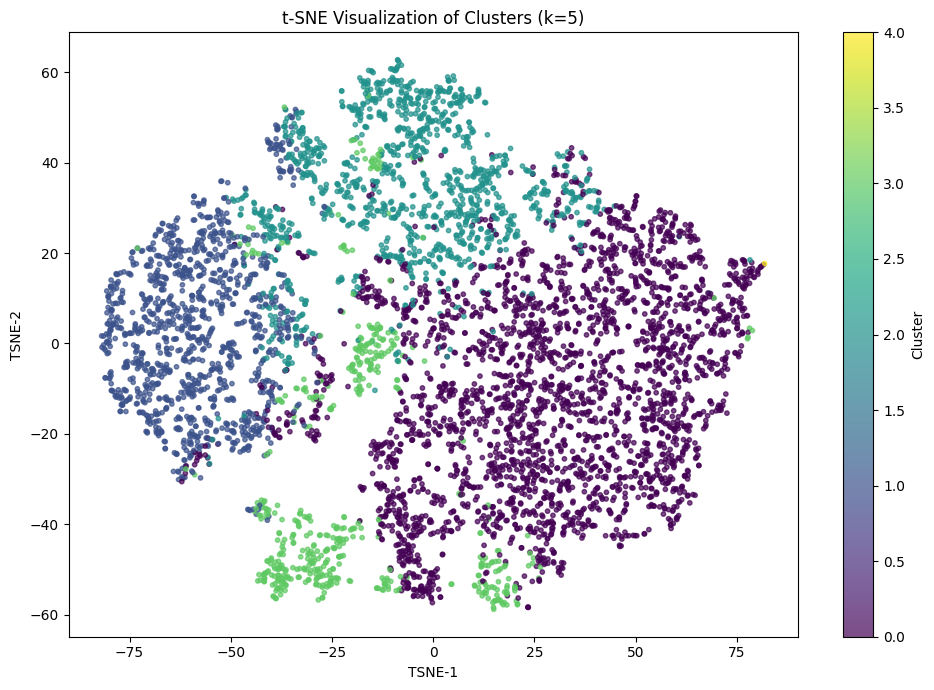

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Reduce to 2D using t-SNE for visualization
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

# Add 2D coordinates to the DataFrame
# Changed 'df' to 'X' to use the correct DataFrame
X['TSNE-1'] = X_tsne[:, 0]
X['TSNE-2'] = X_tsne[:, 1]

# Plot the t-SNE projection with clusters
plt.figure(figsize=(10, 7))
# Changed 'df' to 'X' for plotting
scatter = plt.scatter(X['TSNE-1'], X['TSNE-2'], c=X['Cluster'], cmap='viridis', s=10, alpha=0.7)
# Updated the title to reflect the correct number of clusters
plt.title("t-SNE Visualization of Clusters (k=5)")
plt.xlabel("TSNE-1")
plt.ylabel("TSNE-2")
plt.colorbar(scatter, label='Cluster')
plt.tight_layout()
plt.show()

<ipython-input-18-379b405923ee>:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['TSNE-1'] = X_tsne[:, 0]
<ipython-input-18-379b405923ee>:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['TSNE-2'] = X_tsne[:, 1]
<ipython-input-18-379b405923ee>:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#r

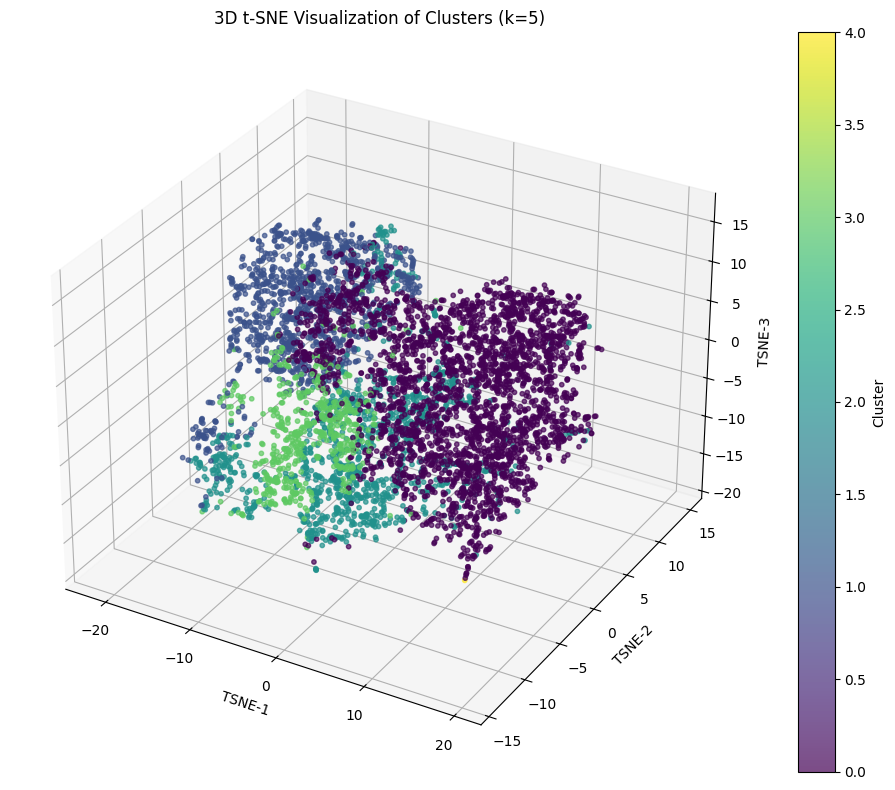

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D # Import Axes3D for 3D plotting

# Reduce to 3D using t-SNE for visualization
# Changed n_components to 3 for 3D visualization
tsne = TSNE(n_components=3, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

# Add 3D coordinates to the DataFrame
X['TSNE-1'] = X_tsne[:, 0]
X['TSNE-2'] = X_tsne[:, 1]
X['TSNE-3'] = X_tsne[:, 2] # This index is now valid

# Plot 3D scatter plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(X['TSNE-1'], X['TSNE-2'], X['TSNE-3'], c=X['Cluster'], cmap='viridis', s=10, alpha=0.7)
ax.set_title("3D t-SNE Visualization of Clusters (k=5)")
ax.set_xlabel("TSNE-1")
ax.set_ylabel("TSNE-2")
ax.set_zlabel("TSNE-3")
fig.colorbar(sc, label="Cluster")
plt.tight_layout()
plt.show()

## Detecting outliers

In [ ]:
iso = IsolationForest(contamination=0.01, random_state=42)
outlier_flags = iso.fit_predict(X_scaled)  # -1 = outlier, 1 = inlier

In [ ]:
# Mark in DataFrame
X_wo = X.copy()
X_wo['Outlier'] = outlier_flags

In [ ]:
# 2. Keep only inliers
X_inliers = X_scaled[outlier_flags == 1]

# 3. Search for best k in [5, 50]
silhouette_scores = []
cluster_range = range(5, 51)

for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_inliers)
    score = silhouette_score(X_inliers, labels)
    silhouette_scores.append(score)

# 4. Best k based on silhouette
best_k = cluster_range[np.argmax(silhouette_scores)]
best_score = max(silhouette_scores)

print(f"Best k after outlier removal: {best_k}, Silhouette Score: {best_score}")

Best k after outlier removal: 5, Silhouette Score: 0.23592307238654017


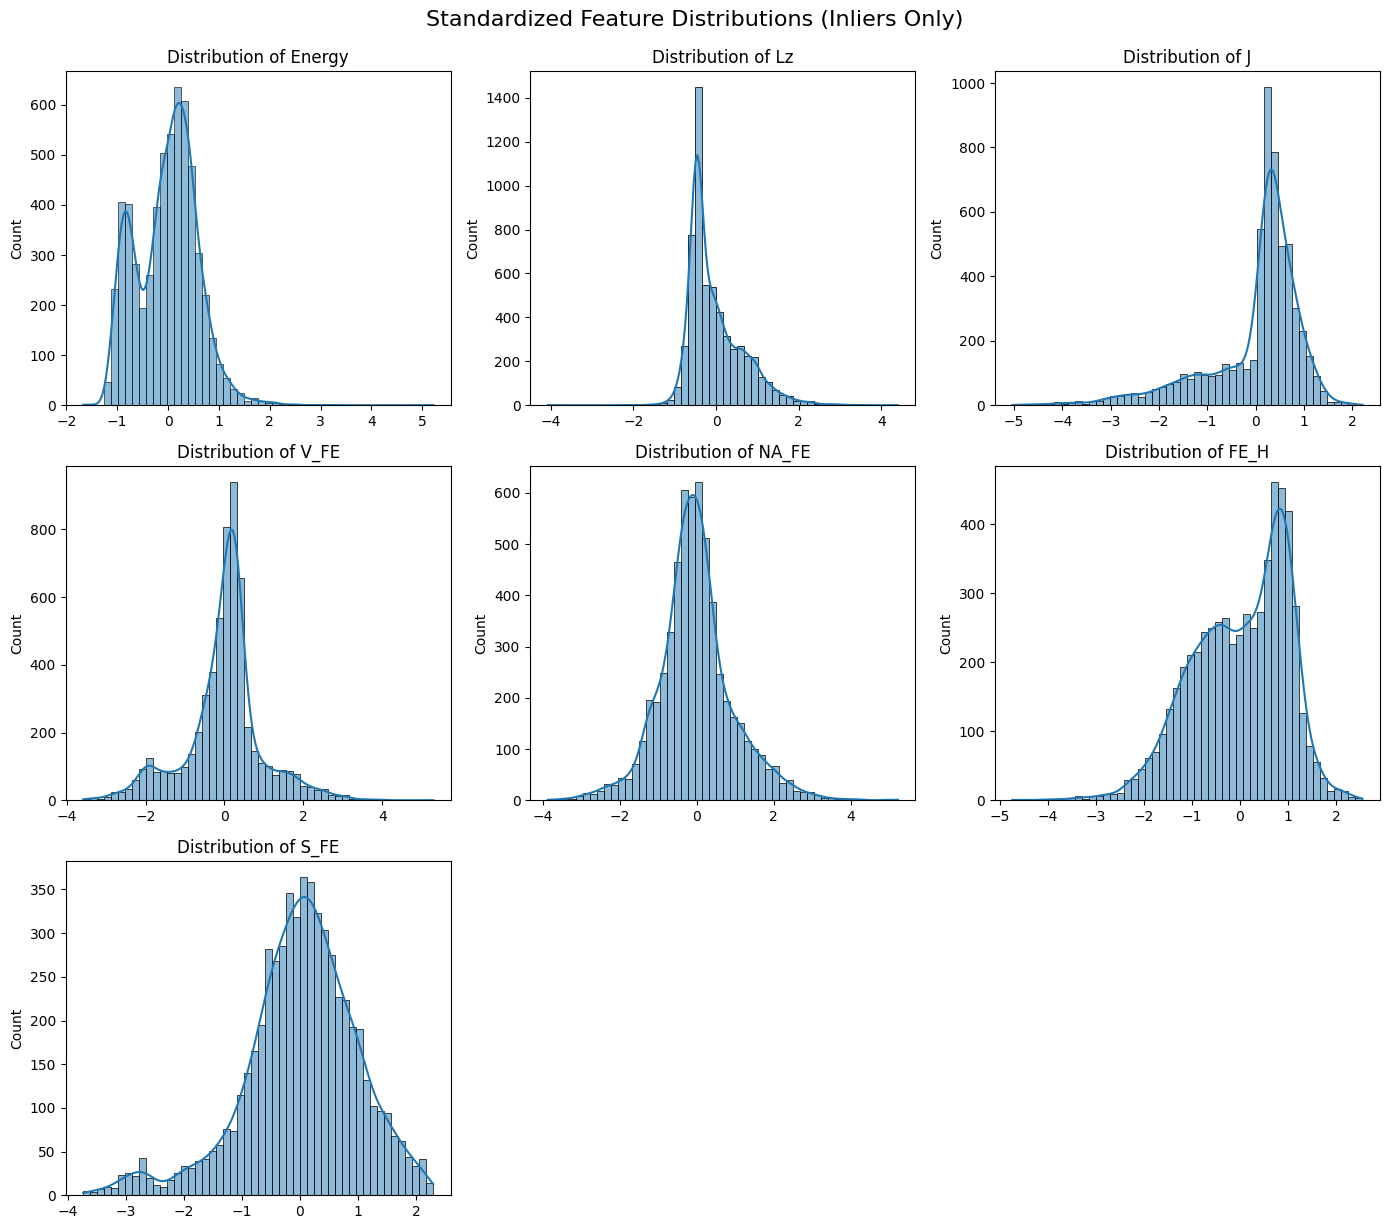

In [ ]:
# Plot distributions for each selected feature
plt.figure(figsize=(14, 12))
for i, col in enumerate(selected_features):
    plt.subplot(3, 3, i + 1)
    # Access the column of the NumPy array X_inliers using its integer index 'i'
    sns.histplot(X_inliers[:, i], bins=50, kde=True)
    plt.title(f'Distribution of {col}')
    plt.tight_layout()

plt.suptitle("Standardized Feature Distributions (Inliers Only)", fontsize=16, y=1.02)
plt.show()

In [ ]:


# Step 3: Cluster only inliers
X_inliers = X_wo[X_wo['Outlier'] == 1]
X_inliers_scaled = X_scaled[X_wo['Outlier'] == 1]

# Apply clustering model (e.g., KMeans)
kmeans = KMeans(n_clusters=5, random_state=42)
X_inliers['Cluster'] = kmeans.fit_predict(X_inliers_scaled)

# Step 4: Merge with original and assign -1 to outliers
X_wo['Cluster'] = -1  # default label
X_wo.loc[X_wo['Outlier'] == 1, 'Cluster'] = X_inliers['Cluster'].values

<ipython-input-23-78f392f3b9da>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_inliers['Cluster'] = kmeans.fit_predict(X_inliers_scaled)


In [ ]:
X_wo['Cluster'].reset_index().to_csv('/content/drive/MyDrive/Applied Machine Learning/Clustering_MohammadhadiShahhosseini_KMeansCheckedOutliers.csv', index=False, header = False)

## GMM

In [ ]:
random_state = 42
# Initialize range and storage
gmm_silhouette_scores = []
cluster_range = range(5, 51)

# Loop over different number of components (clusters)
for k in cluster_range:
    gmm = GaussianMixture(n_components=k, random_state=42)
    labels = gmm.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    gmm_silhouette_scores.append(score)

# Find the best k
best_gmm_k = cluster_range[np.argmax(gmm_silhouette_scores)]
best_gmm_score = max(gmm_silhouette_scores)

best_gmm_k, best_gmm_score

(6, np.float64(0.11709182851038112))

In [ ]:
for k, score in zip(cluster_range, gmm_silhouette_scores):
    print(f"k = {k}, silhouette = {score}")

k = 5, silhouette = 0.06783294986893429
k = 6, silhouette = 0.11709182851038112
k = 7, silhouette = 0.10020782091474986
k = 8, silhouette = 0.060350107334977816
k = 9, silhouette = 0.05138664744891293
k = 10, silhouette = 0.04166188847727402
k = 11, silhouette = 0.0400125680316617
k = 12, silhouette = 0.03522405661527787
k = 13, silhouette = 0.05338771199339692
k = 14, silhouette = 0.04892603879050261
k = 15, silhouette = 0.0425994743946823
k = 16, silhouette = 0.04623780735687608
k = 17, silhouette = 0.03653389684679177
k = 18, silhouette = 0.02197557899474503
k = 19, silhouette = 0.025513242488608787
k = 20, silhouette = 0.027913768948634992
k = 21, silhouette = 0.01607289865493311
k = 22, silhouette = 0.012314803899875146
k = 23, silhouette = 0.006125735261336012
k = 24, silhouette = 0.006218470736187901
k = 25, silhouette = 0.010721909036804355
k = 26, silhouette = -0.006850955078946688
k = 27, silhouette = -0.0023144859635464547
k = 28, silhouette = 0.008818637988440927
k = 29, si

In [ ]:
gmm = GaussianMixture(n_components=best_gmm_k, random_state=42)
gmm_labels = gmm.fit_predict(X_scaled)

# Assign to DataFrame
X = X.copy()
X['GMM_Cluster'] = gmm_labels

# Evaluate
gmm_silhouette = silhouette_score(X_scaled, gmm_labels)
print("GMM Silhouette Score:", gmm_silhouette)

GMM Silhouette Score: 0.11709182851038112


In [ ]:
X['GMM_Cluster'].reset_index().to_csv(
    '/content/drive/MyDrive/Applied Machine Learning/Clustering_MohammadhadiShahhosseini_GMM.csv',
    index=False,
    header=False
)